<a href="https://colab.research.google.com/github/ursu-mihai77777/SpamDetector/blob/main/spamdetector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

import nltk

nltk.download('punkt_tab')

In [20]:
import os
import json

# Definim datele tale de acces (introdu șirul JSON primit de la Kaggle între ghilimele)
# Exemplu de format: '{"username":"numele_tau","key":"a1b2c3d4..."}'
kaggle_data = 'KGAT_40fc0970094cc193ddd91660bea07bd4'

# Creăm folderul de configurare necesar pentru Kaggle
os.makedirs('/root/.kaggle', exist_ok=True)

# Scriem textul direct într-un fișier numit kaggle.json
with open('/root/.kaggle/kaggle.json', 'w') as f:
    f.write(kaggle_data)

# Setăm permisiunile de securitate stricte cerute de Kaggle
!chmod 600 /root/.kaggle/kaggle.json

print("Fișierul kaggle.json a fost creat și configurat cu succes!")


Fișierul kaggle.json a fost creat și configurat cu succes!


In [21]:
from google.colab import files
import os

# 1. Îți va apărea un buton "Choose Files". Apasă-l și selectează fișierul kaggle.json descărcat de pe Kaggle.
uploaded = files.upload()

# 2. Crează folderul de configurare și mută fișierul unde trebuie
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/

# 3. Setează permisiunile de securitate cerute de Kaggle
!chmod 600 /root/.kaggle/kaggle.json

print("Gata! Token-ul a fost instalat cu succes.")

Saving kaggle.json to kaggle (1).json
Gata! Token-ul a fost instalat cu succes.


In [17]:
!pip install nltk
import nltk
from nltk.corpus import stopwords    # For stopwords

# Downloading NLTK data
nltk.download('stopwords')   # Downloading stopwords data
nltk.download('punkt')       # Downloading tokenizer data

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [26]:
import kagglehub
import pandas as pd
import os

# Download the dataset using kagglehub
path = kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")

# Load the specific CSV file from the downloaded dataset path
ceas_path = os.path.join(path, 'CEAS_08.csv')
ceas = pd.read_csv(ceas_path)

print("Dataset loaded successfully. Shape:", ceas.shape)

Using Colab cache for faster access to the 'phishing-email-dataset' dataset.
Dataset loaded successfully. Shape: (39154, 7)


In [28]:
import os

# The dataset directory is stored in the 'path' variable from cell wOfPSBFZkLNf
# spam = pd.read_csv(os.path.join(path, 'SpamAssasin.csv'))
ceas = pd.read_csv(os.path.join(path, 'CEAS_08.csv'))
# ling = pd.read_csv(os.path.join(path, 'Ling.csv'))
# enron = pd.read_csv(os.path.join(path, 'Enron.csv'))
# nazario = pd.read_csv(os.path.join(path, 'Nazario.csv'))
# nigerian = pd.read_csv(os.path.join(path, 'Nigerian_Fraud.csv'))
# phishing = pd.read_csv(os.path.join(path, 'phishing_email.csv'))

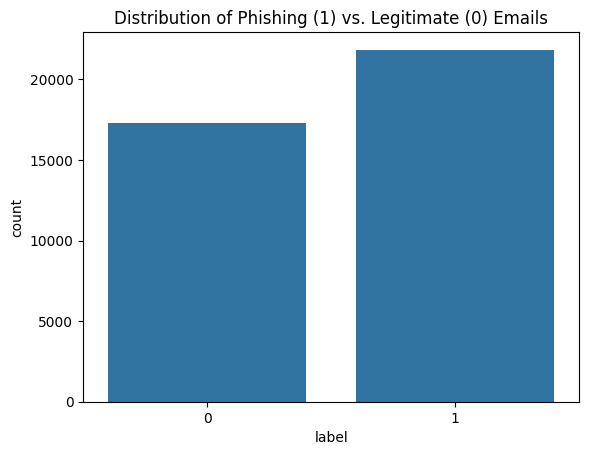

Shape: (39154, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']

Label distribution:
label
1    21842
0    17312
Name: count, dtype: int64

Missing values:
sender        0
receiver    462
date          0
subject      28
body          0
label         0
urls          0
dtype: int64

Duplicates: 0


,sender,receiver,date,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


In [29]:
sns.countplot(x='label', data=ceas)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {ceas.shape}')
print(f'Columns: {list(ceas.columns)}')
print('\nLabel distribution:')
print(ceas['label'].value_counts())
print('\nMissing values:')
print(ceas.isnull().sum())
print(f'\nDuplicates: {ceas.duplicated().sum()}')

ceas.head()

In [30]:
ceas.drop(columns = ['date'], inplace = True)

In [31]:
ceas.head()

,sender,receiver,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


In [32]:
#check duplicate values
ceas.duplicated().sum()

np.int64(0)

In [33]:
ceas.shape

(39154, 6)

In [34]:
values = ceas['label'].value_counts()
total = values.sum()

percentage_0 = (values[0] /total) * 100
percentage_1 = (values[1]/ total) *100

print('percentage of 0 :' ,percentage_0)
print('percentage of 1 :' ,percentage_1)

percentage of 0 : 44.21515043162895
percentage of 1 : 55.784849568371044


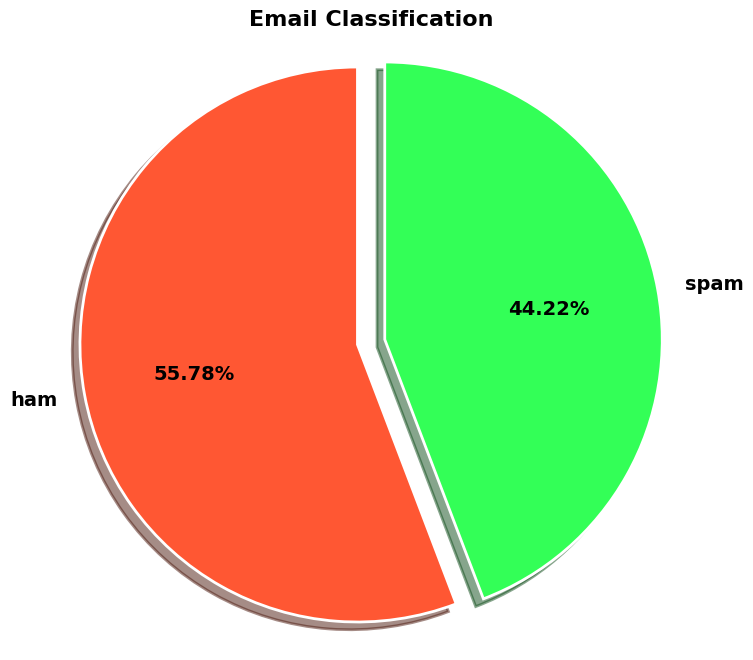

In [35]:
import matplotlib.pyplot as plt

# Sample data
# values = [75, 25]  # Example values for 'ham' and 'spam'

# Define custom colors
colors = ['#FF5733', '#33FF57']

# Define the explode parameter to create a gap between slices
explode = (0, 0.1)  # Explode the second slice (spam) by 10%

# Create a figure with a white background
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_facecolor('white')

# Create the pie chart with custom colors, labels, explode parameter, and shadow
wedges, texts, autotexts = ax.pie(
    values, labels=['ham', 'spam'],
    autopct='%0.2f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
    explode=explode,  # Apply the explode parameter
    shadow=True  # Add shadow
)

# Customize text properties
for text, autotext in zip(texts, autotexts):
    text.set(size=14, weight='bold')
    autotext.set(size=14, weight='bold')

# Add a title
ax.set_title('Email Classification', fontsize=16, fontweight='bold')

# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# Show the pie chart
plt.show()

In [38]:

ceas['num_characters'] = ceas['body'].apply(len)
ceas['num_words'] = ceas['body'].apply(lambda x: len(nltk.word_tokenize(x)))
ceas['num_sentence'] = ceas['body'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [40]:
ceas[['num_characters', 'num_words', 'num_sentence']].describe()

,num_characters,num_words,num_sentence
count,39154.000000,39154.000000,39154.000000
mean,1571.079813,269.667492,10.665449
std,3615.810576,655.018917,19.582262
min,14.000000,1.000000,1.000000
25%,224.000000,40.000000,3.000000
50%,570.000000,106.000000,5.000000
75%,1643.000000,321.000000,11.000000
max,143996.000000,28294.000000,893.000000


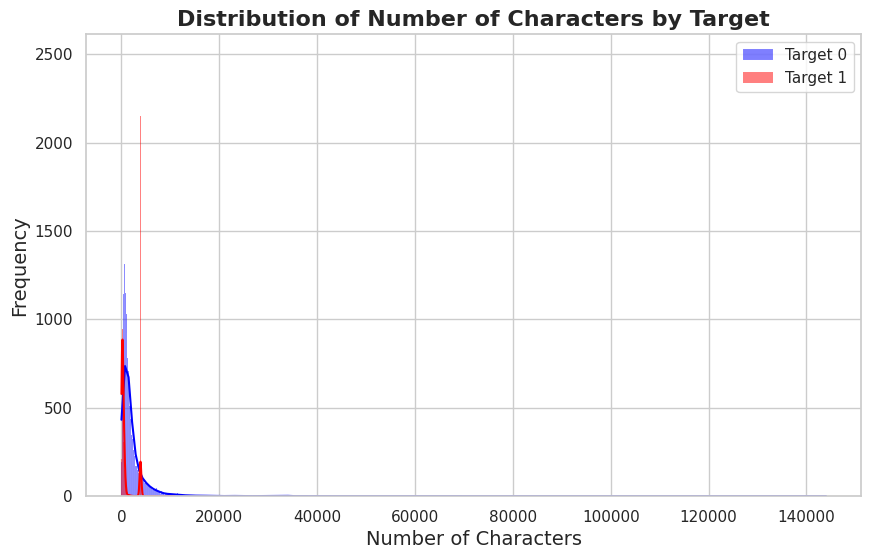

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a figure and set the figure size
plt.figure(figsize=(10, 6))

# Plot the histogram for target 0 in blue
sns.histplot(ceas[ceas['label'] == 0]['num_characters'], color='blue', label='Target 0', kde=True)

# Plot the histogram for target 1 in red
sns.histplot(ceas[ceas['label'] == 1]['num_characters'], color='red', label='Target 1', kde=True)

# Add labels and a title
plt.xlabel('Number of Characters', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.title('Distribution of Number of Characters by Target', fontsize=16, fontweight='bold')

# Add a legend
plt.legend()

# Customize the appearance of the plot
sns.set(style='whitegrid')  # Add a white grid background

# Show the plot
plt.show()